In [1]:
import os
import shutil
from pathlib import Path
from PIL import ImageFile
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import warnings
from collections import Counter

warnings.filterwarnings('ignore')

ImageFile.LOAD_TRUNCATED_IMAGES = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

input_dir = Path("/kaggle/input")
unified_dir = Path("/tmp/disaster_data")

if unified_dir.exists():
    shutil.rmtree(unified_dir)
unified_dir.mkdir(parents=True, exist_ok=True)

base_path = next((p.parent for p in input_dir.rglob("disaster_dataset") if p.is_dir() and (p / "disaster_dataset").exists()), None)

# Copy the classes into a unified directory
nested_dir = base_path / "disaster_dataset" / "disaster_dataset"
for folder in nested_dir.iterdir():
    if folder.is_dir():
        shutil.copytree(folder, unified_dir / folder.name)

eq_dir = base_path / "earthquake"
if not eq_dir.exists():
    eq_dir = base_path / "disaster_dataset" / "earthquake"
if eq_dir.exists():
    shutil.copytree(eq_dir, unified_dir / "Earthquake")

# Data Augmentation & Loading
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

full_dataset = datasets.ImageFolder(root=str(unified_dir), transform=train_transform)
classes = full_dataset.classes
num_classes = len(classes)

torch.manual_seed(42)
train_size = int(0.8 * len(full_dataset))
test_size = len(full_dataset) - train_size
train_set, test_set = random_split(full_dataset, [train_size, test_size])
test_set.dataset.transform = test_transform

train_loader = DataLoader(train_set, batch_size=32, shuffle=True, num_workers=2)
test_loader = DataLoader(test_set, batch_size=32, shuffle=False, num_workers=2)

print(f"Dataset ready! Found {num_classes} classes: {classes}")

# Extract exact labels present in the test split
test_targets = [full_dataset.targets[i] for i in test_set.indices]
counts = Counter(test_targets)

for idx, class_name in enumerate(classes):
    print(f"{class_name}: Test = {counts[idx]}")

Using device: cuda
Dataset ready! Found 6 classes: ['Earthquake', 'fire', 'flood', 'landslide', 'normal', 'smoke']
Earthquake: Test = 214
fire: Test = 489
flood: Test = 536
landslide: Test = 59
normal: Test = 447
smoke: Test = 72


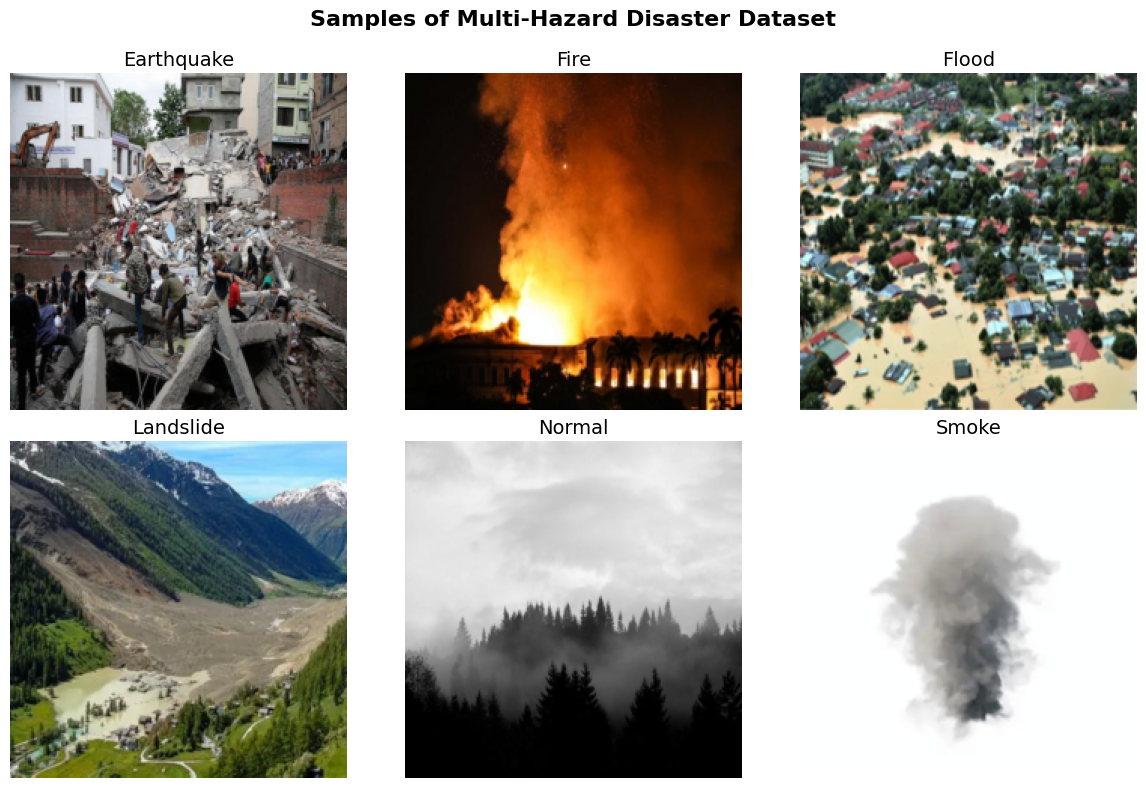

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Create a 2x3 grid for the 6 classes
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
fig.suptitle("Samples of Multi-Hazard Disaster Dataset", fontsize=16, fontweight='bold')
axes = axes.flatten()

class_found = {c: False for c in classes}
images_plotted = 0

# Scan the dataset to find one image per class
for img, label in full_dataset:
    class_name = classes[label]
    if not class_found[class_name]:
        # Un-normalize the image so it looks normal to the human eye
        img = img.numpy().transpose((1, 2, 0))
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img = std * img + mean
        img = np.clip(img, 0, 1)
        
        # Plot the image
        axes[images_plotted].imshow(img)
        axes[images_plotted].set_title(class_name.capitalize(), fontsize=14)
        axes[images_plotted].axis('off')
        
        class_found[class_name] = True
        images_plotted += 1
        
    if images_plotted == 6:
        break

plt.tight_layout()
plt.subplots_adjust(top=0.90)
plt.show()

In [3]:
# --- REUSABLE CONFUSION MATRIX FUNCTION ---
def generate_confusion_matrix(model, data_loader, title):
    model.eval()
    all_preds, all_labels = [], []
    correct, total = 0, 0
    
    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
            
            correct += torch.sum(preds.cpu() == labels).item()
            total += labels.size(0)

    acc = (correct / total) * 100
    print(f"\n>> [{title}] Accuracy: {acc:.2f}%")

    cm = confusion_matrix(all_labels, all_preds)
    cm_normalized = cm.astype('float') / (cm.sum(axis=1)[:, np.newaxis] + 1e-10)

    plt.figure(figsize=(7, 5))
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues', 
                xticklabels=classes, yticklabels=classes)
    plt.title(f"{title} (Accuracy: {acc:.2f}%)")
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.tight_layout()
    plt.show()

# --- REUSABLE TRAINING & FINE-TUNING PIPELINE ---
def train_simple_and_finetune(model, model_name, head_params):
    criterion = nn.CrossEntropyLoss()
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    
    print(f"\n{'='*55}")
    print(f"   STARTING WORKFLOW: {model_name.upper()}")
    print(f"{'='*55}")

    def run_epoch(optimizer, is_training):
        model.train() if is_training else model.eval()
        loader = train_loader if is_training else test_loader
        running_loss, correct, total = 0.0, 0, 0
        
        with torch.set_grad_enabled(is_training):
            for images, labels in loader:
                images, labels = images.to(device), labels.to(device)
                if is_training:
                    optimizer.zero_grad()
                outputs = model(images)
                loss = criterion(outputs, labels)
                if is_training:
                    loss.backward()
                    optimizer.step()
                
                running_loss += loss.item() * images.size(0)
                _, preds = torch.max(outputs, 1)
                correct += torch.sum(preds == labels).item()
                total += labels.size(0)
                
        return running_loss / total, (correct / total) * 100

    # 1. BASELINE EVALUATION
    print("\n[Step 1] Evaluating Baseline (Completely Untrained Head)...")
    generate_confusion_matrix(model, test_loader, f"{model_name} - Baseline")

    # 2. STAGE 1: SIMPLE MODEL TRAINING
    print("\n--- STAGE 1: SIMPLE MODEL TRAINING (Backbone Frozen) ---")
    optimizer_stage1 = optim.Adam(head_params, lr=1e-3)
    for epoch in range(2):
        t_loss, t_acc = run_epoch(optimizer_stage1, is_training=True)
        v_loss, v_acc = run_epoch(optimizer_stage1, is_training=False)
        history['train_loss'].append(t_loss); history['val_loss'].append(v_loss)
        history['train_acc'].append(t_acc); history['val_acc'].append(v_acc)
        print(f"Stage 1 - Ep [{epoch+1}/2] Train Loss: {t_loss:.4f} | Val Loss: {v_loss:.4f} | Train Acc: {t_acc:.2f}% | Val Acc: {v_acc:.2f}%")

    # 3. STAGE 2: FULL FINE-TUNING
    print("\n--- STAGE 2: FULL FINE-TUNING (Unfreezing All Layers) ---")
    for param in model.parameters():
        param.requires_grad = True
    optimizer_stage2 = optim.Adam(model.parameters(), lr=1e-5)
    
    for epoch in range(3):
        t_loss, t_acc = run_epoch(optimizer_stage2, is_training=True)
        v_loss, v_acc = run_epoch(optimizer_stage2, is_training=False)
        history['train_loss'].append(t_loss); history['val_loss'].append(v_loss)
        history['train_acc'].append(t_acc); history['val_acc'].append(v_acc)
        print(f"Stage 2 - Ep [{epoch+1}/3] Train Loss: {t_loss:.4f} | Val Loss: {v_loss:.4f} | Train Acc: {t_acc:.2f}% | Val Acc: {v_acc:.2f}%")

    # 4. SAVE MODEL WEIGHTS LOCALLY
    clean_name = model_name.replace(" ", "_").replace("/", "_").replace("(", "").replace(")", "").lower()
    save_path = f"/kaggle/working/{clean_name}.pth"
    torch.save(model.state_dict(), save_path)
    print(f"\n[Saved] Weights saved to {save_path}")

    # 5. POST-TRAINING CONFUSION MATRICES
    print("\n[Step 5] Plotting Final Confusion Matrices...")
    generate_confusion_matrix(model, test_loader, f"{model_name} - Final TESTING Set")

    return history

Loading Vision Transformer (ViT)...
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 197MB/s]



   STARTING WORKFLOW: VISION TRANSFORMER (VIT-B/16)

[Step 1] Evaluating Baseline (Completely Untrained Head)...

>> [Vision Transformer (ViT-B/16) - Baseline] Accuracy: 11.83%


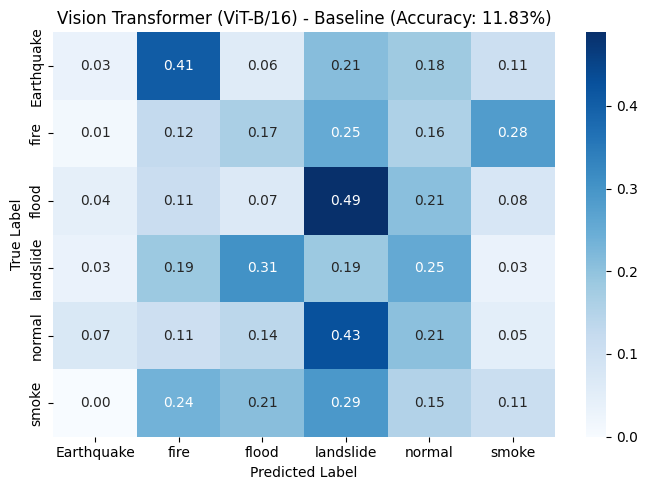


--- STAGE 1: SIMPLE MODEL TRAINING (Backbone Frozen) ---
Stage 1 - Ep [1/2] Train Loss: 0.3736 | Val Loss: 0.2117 | Train Acc: 89.39% | Val Acc: 93.62%
Stage 1 - Ep [2/2] Train Loss: 0.1556 | Val Loss: 0.1688 | Train Acc: 95.59% | Val Acc: 94.50%

--- STAGE 2: FULL FINE-TUNING (Unfreezing All Layers) ---
Stage 2 - Ep [1/3] Train Loss: 0.0853 | Val Loss: 0.0844 | Train Acc: 97.45% | Val Acc: 97.41%
Stage 2 - Ep [2/3] Train Loss: 0.0168 | Val Loss: 0.0789 | Train Acc: 99.81% | Val Acc: 97.36%
Stage 2 - Ep [3/3] Train Loss: 0.0064 | Val Loss: 0.0747 | Train Acc: 99.93% | Val Acc: 97.91%

[Saved] Weights saved to /kaggle/working/vision_transformer_vit-b_16.pth

[Step 5] Plotting Final Confusion Matrices...

>> [Vision Transformer (ViT-B/16) - Final TESTING Set] Accuracy: 97.91%


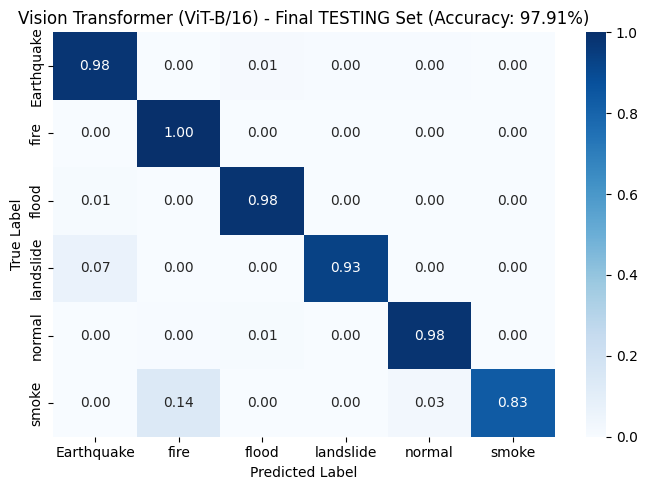


Loading Swin Transformer...
Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /root/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:00<00:00, 199MB/s] 



   STARTING WORKFLOW: SWIN TRANSFORMER

[Step 1] Evaluating Baseline (Completely Untrained Head)...

>> [Swin Transformer - Baseline] Accuracy: 14.58%


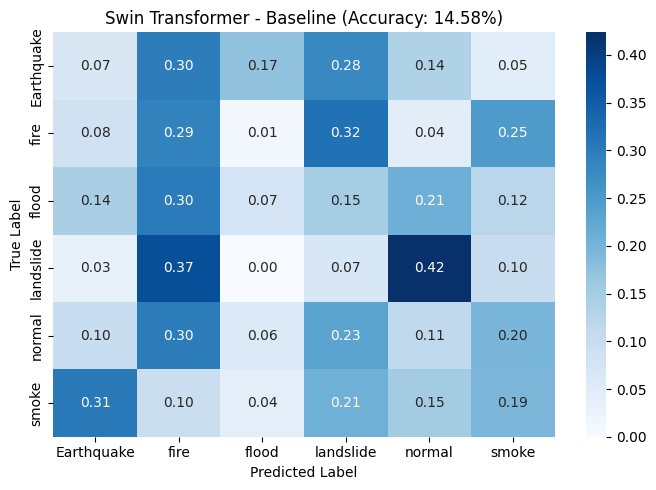


--- STAGE 1: SIMPLE MODEL TRAINING (Backbone Frozen) ---
Stage 1 - Ep [1/2] Train Loss: 0.3900 | Val Loss: 0.1955 | Train Acc: 89.37% | Val Acc: 94.17%
Stage 1 - Ep [2/2] Train Loss: 0.1674 | Val Loss: 0.1511 | Train Acc: 95.24% | Val Acc: 95.82%

--- STAGE 2: FULL FINE-TUNING (Unfreezing All Layers) ---
Stage 2 - Ep [1/3] Train Loss: 0.1016 | Val Loss: 0.0972 | Train Acc: 96.67% | Val Acc: 97.03%
Stage 2 - Ep [2/3] Train Loss: 0.0536 | Val Loss: 0.0809 | Train Acc: 98.49% | Val Acc: 97.85%
Stage 2 - Ep [3/3] Train Loss: 0.0351 | Val Loss: 0.0654 | Train Acc: 99.06% | Val Acc: 98.46%

[Saved] Weights saved to /kaggle/working/swin_transformer.pth

[Step 5] Plotting Final Confusion Matrices...

>> [Swin Transformer - Final TESTING Set] Accuracy: 98.46%


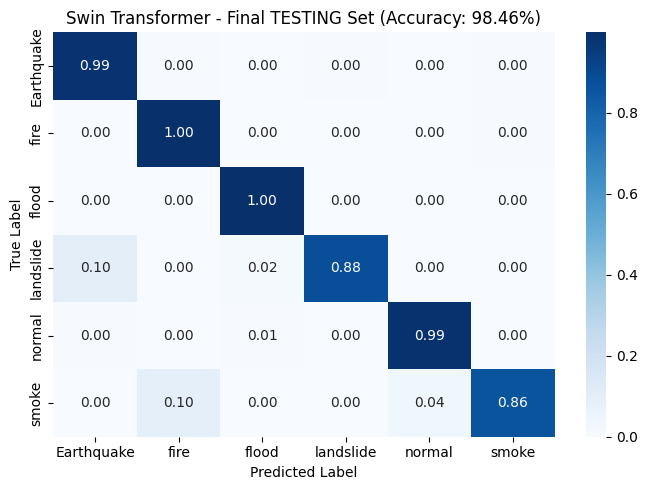


All models and training histories saved successfully to /kaggle/working!


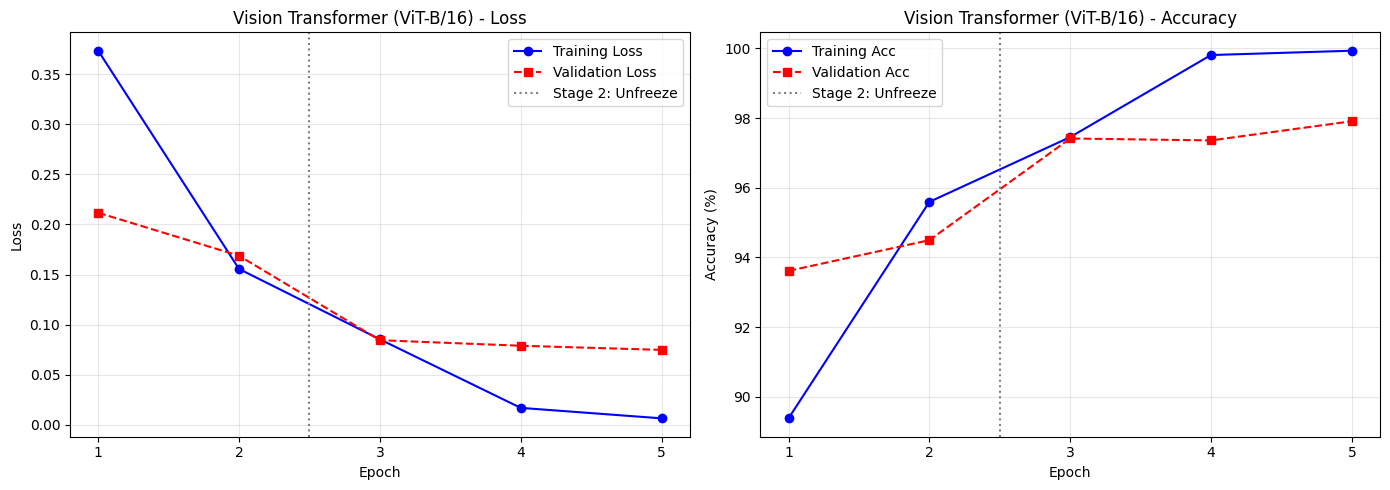

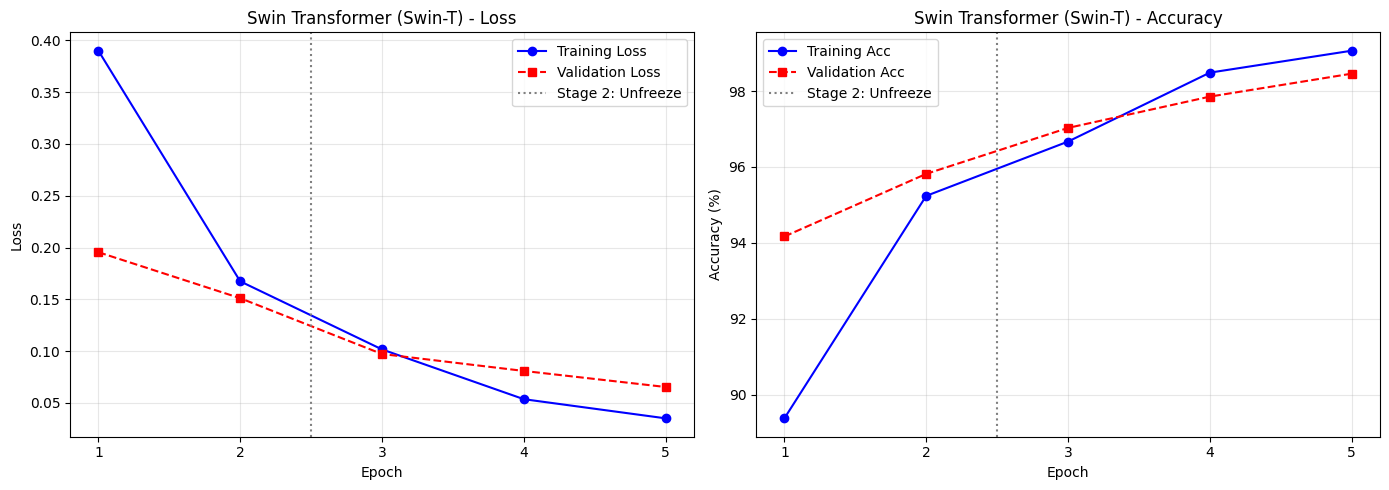

In [4]:
import json
import matplotlib.pyplot as plt

# ==========================================
# 1. VISION TRANSFORMER (ViT-B/16)
# ==========================================
print("Loading Vision Transformer (ViT)...")
vit = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
for param in vit.parameters(): param.requires_grad = False
vit.heads.head = nn.Linear(vit.heads.head.in_features, num_classes)
vit = vit.to(device)

vit_history = train_simple_and_finetune(vit, "Vision Transformer (ViT-B/16)", vit.heads.head.parameters())

with open("/kaggle/working/vit_history.json", "w") as f:
    json.dump(vit_history, f)

# ==========================================
# 2. SWIN TRANSFORMER (Swin-T)
# ==========================================
print("\nLoading Swin Transformer...")
swin = models.swin_t(weights=models.Swin_T_Weights.DEFAULT)
for param in swin.parameters(): param.requires_grad = False
swin.head = nn.Linear(swin.head.in_features, num_classes)
swin = swin.to(device)

swin_history = train_simple_and_finetune(swin, "Swin Transformer", swin.head.parameters())

with open("/kaggle/working/swin_history.json", "w") as f:
    json.dump(swin_history, f)

print("\nAll models and training histories saved successfully to /kaggle/working!")

# ==========================================
# 3. GENERATE LEARNING CURVES FOR PAPER
# ==========================================
def plot_learning_curves(history, title, filename):
    epochs = range(1, 6)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Loss Plot
    ax1.plot(epochs, history['train_loss'], 'b-o', label='Training Loss')
    ax1.plot(epochs, history['val_loss'], 'r--s', label='Validation Loss')
    ax1.axvline(x=2.5, color='gray', linestyle=':', label='Stage 2: Unfreeze')
    ax1.set_title(f'{title} - Loss')
    ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
    ax1.legend(); ax1.grid(True, alpha=0.3)
    ax1.set_xticks(epochs)

    # Accuracy Plot
    ax2.plot(epochs, history['train_acc'], 'b-o', label='Training Acc')
    ax2.plot(epochs, history['val_acc'], 'r--s', label='Validation Acc')
    ax2.axvline(x=2.5, color='gray', linestyle=':', label='Stage 2: Unfreeze')
    ax2.set_title(f'{title} - Accuracy')
    ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy (%)')
    ax2.legend(); ax2.grid(True, alpha=0.3)
    ax2.set_xticks(epochs)

    plt.tight_layout()
    plt.savefig(f"/kaggle/working/{filename}.png", dpi=300)
    plt.show()

plot_learning_curves(vit_history, "Vision Transformer (ViT-B/16)", "vit_learning_curves")
plot_learning_curves(swin_history, "Swin Transformer (Swin-T)", "swin_learning_curves")


   SWIN TRANSFORMER TEST SET METRICS
Test Accuracy: 98.46%
Precision:     0.9773
Recall:        0.9519
Sensitivity:   0.9519
F1-Score:      0.9637
[Saved] Raw testing data saved to /kaggle/working/swin_transformer_test_results.npz (Download this!)


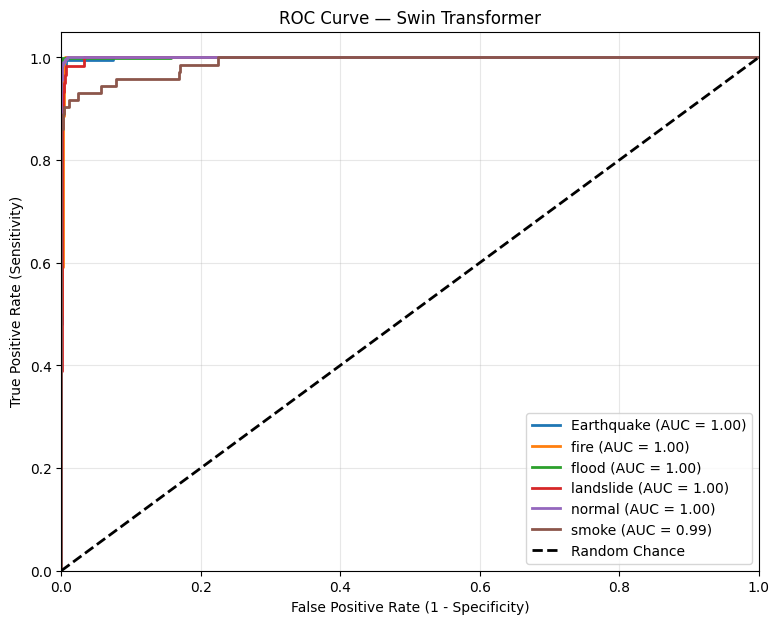


   VISION TRANSFORMER (VIT-B/16) TEST SET METRICS
Test Accuracy: 97.91%
Precision:     0.9776
Recall:        0.9512
Sensitivity:   0.9512
F1-Score:      0.9632
[Saved] Raw testing data saved to /kaggle/working/vision_transformer_vit-b_16_test_results.npz (Download this!)


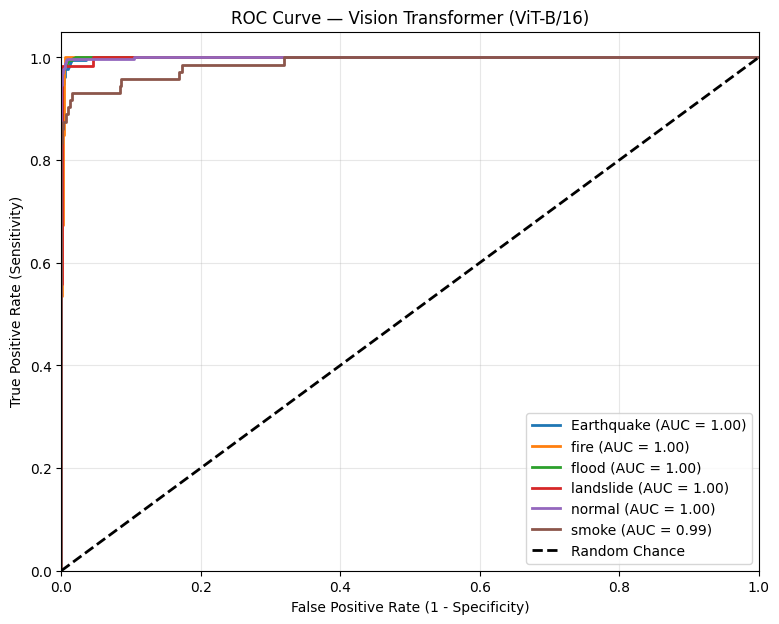

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc
from sklearn.preprocessing import label_binarize
import os

def evaluate_transformers_and_save(model, model_name):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []

    # Run the test set through the trained model
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            
            # Get probabilities for ROC
            probs = torch.softmax(outputs, dim=1)
            all_probs.extend(probs.cpu().numpy())
            
            # Get final predictions for metrics
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    # Calculate Metrics
    acc = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    recall = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)

    print(f"\n==========================================")
    print(f"   {model_name.upper()} TEST SET METRICS")
    print(f"==========================================")
    print(f"Test Accuracy: {acc * 100:.2f}%")
    print(f"Precision:     {precision:.4f}")
    print(f"Recall:        {recall:.4f}")
    print(f"Sensitivity:   {recall:.4f}")
    print(f"F1-Score:      {f1:.4f}")

    # --- NEW: SAVE RAW PREDICTIONS LOCALLY (Bypasses the 5GB dataset need) ---
    clean_name = model_name.replace(" ", "_").replace("/", "_").replace("(", "").replace(")", "").lower()
    save_path = f"/kaggle/working/{clean_name}_test_results.npz"
    np.savez(save_path, y_true=all_labels, y_pred=all_preds, y_probs=all_probs, classes=classes)
    print(f"[Saved] Raw testing data saved to {save_path} (Download this!)")

    # Generate Multi-Class ROC Curve
    binarized_labels = label_binarize(all_labels, classes=[i for i in range(num_classes)])
    plt.figure(figsize=(9, 7))
    for i in range(num_classes):
        fpr, tpr, _ = roc_curve(binarized_labels[:, i], all_probs[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f'{classes[i]} (AUC = {roc_auc:.2f})')

    plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Chance')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate (1 - Specificity)')
    plt.ylabel('True Positive Rate (Sensitivity)')
    plt.title(f'ROC Curve — {model_name}')
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    
    # Save the ROC plot just in case
    plt.savefig(f"/kaggle/working/{clean_name}_roc.png", dpi=300)
    plt.show()

# Extract test metrics, save data, and plot graphs for both models
evaluate_transformers_and_save(swin, "Swin Transformer")
evaluate_transformers_and_save(vit, "Vision Transformer (ViT-B/16)")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


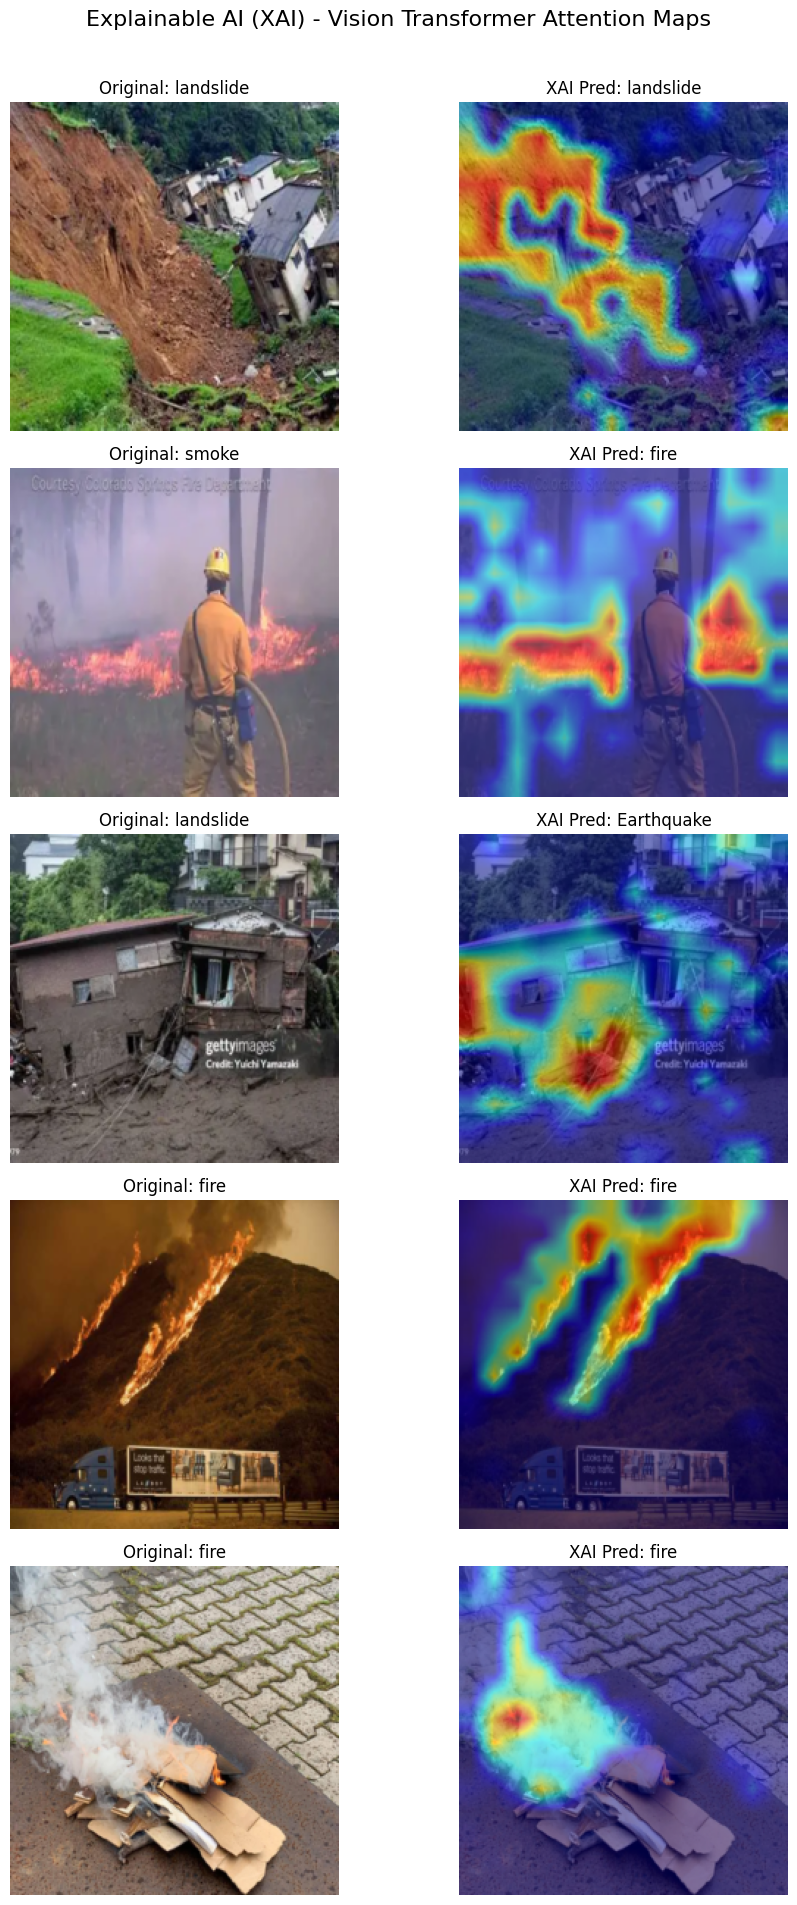

In [6]:
!pip install grad-cam -q

import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

# 1. Define the reshape function specifically for Vision Transformers
# ViT processes images as flat sequences of 196 patches (plus 1 class token).
# We have to reshape it back into a 2D grid (14x14) so we can draw a picture.
def reshape_transform(tensor, height=14, width=14):
    result = tensor[:, 1:, :].reshape(tensor.size(0), height, width, tensor.size(2))
    result = result.transpose(2, 3).transpose(1, 2)
    return result

# 2. Set the target layer for ViT (the final encoder block)
target_layers = [vit.encoder.layers[-1].ln_1]

# 3. Initialize the XAI CAM object
cam = GradCAM(model=vit, target_layers=target_layers, reshape_transform=reshape_transform)

# 4. Grab a single batch of images from the test set
vit.eval()
dataiter = iter(test_loader)
images, labels = next(dataiter)
images = images.to(device)

# 5. Plot 5 random images with their XAI Heatmaps
fig, axes = plt.subplots(5, 2, figsize=(10, 20))
fig.suptitle("Explainable AI (XAI) - Vision Transformer Attention Maps", fontsize=16)

for i in range(5):
    input_tensor = images[i].unsqueeze(0)
    true_label = classes[labels[i].item()]
    
    # Get model prediction
    with torch.no_grad():
        output = vit(input_tensor)
        predicted_idx = torch.argmax(output, 1).item()
        pred_label = classes[predicted_idx]
    
    # Generate the heatmap
    grayscale_cam = cam(input_tensor=input_tensor, targets=None)[0, :]
    
    # De-normalize the original image to display it properly
    img = images[i].cpu().numpy().transpose(1, 2, 0)
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    
    # Overlay the heatmap on the image
    visualization = show_cam_on_image(img, grayscale_cam, use_rgb=True)
    
    # Plot Original
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"Original: {true_label}")
    axes[i, 0].axis('off')
    
    # Plot XAI Heatmap
    axes[i, 1].imshow(visualization)
    axes[i, 1].set_title(f"XAI Pred: {pred_label}")
    axes[i, 1].axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.show()

In [7]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

def generate_per_class_table(model, dataloader, model_name="Model"):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    cm = confusion_matrix(all_labels, all_preds)
    total_samples = np.sum(cm)
    records = []

    for i, class_name in enumerate(classes):
        tp = cm[i, i]
        fp = np.sum(cm[:, i]) - tp
        fn = np.sum(cm[i, :]) - tp
        tn = total_samples - (tp + fp + fn)

        accuracy = ((tp + tn) / total_samples) * 100
        precision = (tp / (tp + fp)) * 100 if (tp + fp) > 0 else 0.0
        fnr = (fn / (fn + tp)) * 100 if (fn + tp) > 0 else 0.0
        specificity = (tn / (tn + fp)) * 100 if (tn + fp) > 0 else 0.0
        mcr = ((fp + fn) / total_samples) * 100

        records.append({
            "Hazard Class": class_name.capitalize(),
            "Accuracy (%)": f"{accuracy:.2f}",
            "Precision (%)": f"{precision:.2f}",
            "FNR (%)": f"{fnr:.2f}",
            "Specificity (%)": f"{specificity:.2f}",
            "MCR (%)": f"{mcr:.2f}"
        })

    df = pd.DataFrame(records)
    print(f"\n--- {model_name} Per-Class Performance Table ---")
    print(df.to_latex(index=False))
    return df

# Run for both models on the test split
generate_per_class_table(vit, test_loader, "ViT-B/16")
generate_per_class_table(swin, test_loader, "Swin-T")


--- ViT-B/16 Per-Class Performance Table ---
\begin{tabular}{llllll}
\toprule
Hazard Class & Accuracy (%) & Precision (%) & FNR (%) & Specificity (%) & MCR (%) \\
\midrule
Earthquake & 99.12 & 95.00 & 2.34 & 99.31 & 0.88 \\
Fire & 99.34 & 97.60 & 0.00 & 99.10 & 0.66 \\
Flood & 99.06 & 98.50 & 1.68 & 99.38 & 0.94 \\
Landslide & 99.72 & 98.21 & 6.78 & 99.94 & 0.28 \\
Normal & 99.28 & 98.87 & 1.79 & 99.64 & 0.72 \\
Smoke & 99.28 & 98.36 & 16.67 & 99.94 & 0.72 \\
\bottomrule
\end{tabular}


--- Swin-T Per-Class Performance Table ---
\begin{tabular}{llllll}
\toprule
Hazard Class & Accuracy (%) & Precision (%) & FNR (%) & Specificity (%) & MCR (%) \\
\midrule
Earthquake & 99.34 & 95.91 & 1.40 & 99.44 & 0.66 \\
Fire & 99.45 & 98.38 & 0.41 & 99.40 & 0.55 \\
Flood & 99.72 & 99.26 & 0.19 & 99.69 & 0.28 \\
Landslide & 99.56 & 98.11 & 11.86 & 99.94 & 0.44 \\
Normal & 99.56 & 99.33 & 1.12 & 99.78 & 0.44 \\
Smoke & 99.28 & 95.38 & 13.89 & 99.83 & 0.72 \\
\bottomrule
\end{tabular}



,Hazard Class,Accuracy (%),Precision (%),FNR (%),Specificity (%),MCR (%)
0,Earthquake,99.34,95.91,1.40,99.44,0.66
1,Fire,99.45,98.38,0.41,99.40,0.55
2,Flood,99.72,99.26,0.19,99.69,0.28
3,Landslide,99.56,98.11,11.86,99.94,0.44
4,Normal,99.56,99.33,1.12,99.78,0.44
5,Smoke,99.28,95.38,13.89,99.83,0.72
